# Using Machine Learning to Solve for RSI SMA period
Selection system: two approaches
- Create an algo that performs sentiment and fundamental analysis on crypto, giving it a score then we pick the best performers
- Identify by price action. Price movement 15m, 1hr, 4hr all positive. Then volume.

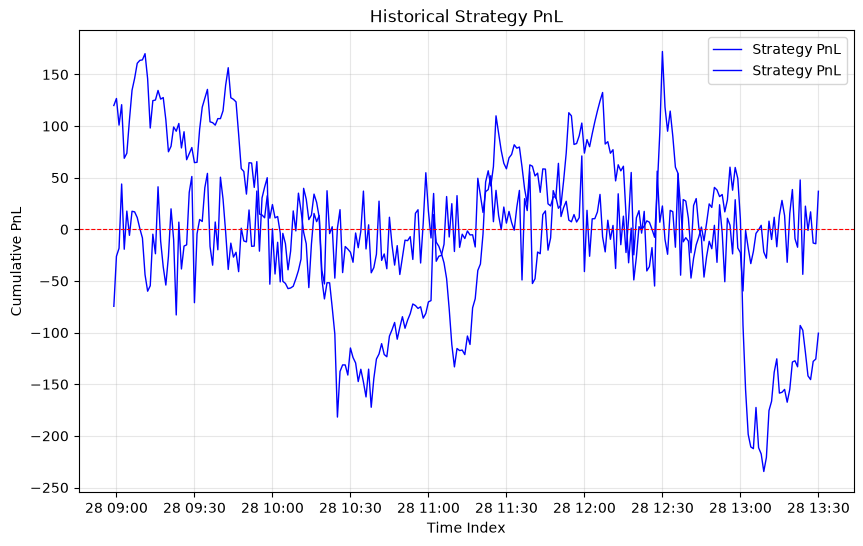

In [17]:
# Add the project root (one level up from /research) to the path
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

import pandas as pd
from utils.indicators import *
from utils.engine import *

df_orderbook = pd.read_csv("./csv/BTCUSDT_orderbook.csv")
df_trades = pd.read_csv("./csv/BTCUSDT_trades.csv")
# Convert unix timestamp to datetime
df_orderbook['datetime'] = pd.to_datetime(df_orderbook['timestamp'], unit='ms')  # change unit to 's' if in seconds
df_trades['datetime'] = pd.to_datetime(df_trades['timestamp'], unit='ms')

# Set datetime as index
df_orderbook = df_orderbook.set_index('datetime')
df_trades = df_trades.set_index('datetime')

# Aggregate orderbook to 1m (mid-price OHLCV style)
df_ob_1m = df_orderbook.resample('1min').agg({
    'bid_price': 'last',
    'ask_price': 'last',
    'bid_amount': 'sum',
    'ask_amount': 'sum',
})

df_ob_1m['mid_price'] = (df_ob_1m['bid_price'] + df_ob_1m['ask_price']) / 2
df_ob_1m['spread'] = df_ob_1m['ask_price'] - df_ob_1m['bid_price']

df_trades['buy_vol']  = df_trades['amount'].where(df_trades['side'] == 'buy', 0)
df_trades['sell_vol'] = df_trades['amount'].where(df_trades['side'] == 'sell', 0)

# Aggregate trades to 1m
df_trades_1m = df_trades.resample('1min').agg({
    'price': ['first', 'max', 'min', 'last', 'count'],
    'amount': 'sum',
    'buy_vol': ['sum', 'max'],
    'sell_vol': ['sum', 'max']
})

# Flatten multi-level columns
df_trades_1m.columns = ['open', 'high', 'low', 'close', 'num_trades', 'volume', 'agg_buyer', 'largest_buyer', 'agg_seller', 'largest_seller']

df_trades_1m = df_trades_1m.dropna(subset=['close'])

df_price_1m = pd.DataFrame({
    'close': df_ob_1m['mid_price'] - df_ob_1m['mid_price'].mean(),
    'largest_buyer': df_trades_1m['largest_buyer'] * 100 / df_trades_1m['volume'],
    'largest_seller': df_trades_1m['largest_seller'] * 100 / df_trades_1m['volume'],
    'OFI': 100*(df_ob_1m['bid_amount'] - df_ob_1m['ask_amount']) / (df_ob_1m['bid_amount'] + df_ob_1m['ask_amount']),
    'cvd': calculate_cvd(df_trades_1m['agg_buyer'], df_trades_1m['agg_seller']),
    'timestamp': df_ob_1m.index,
})

plot_one(df_price_1m[['close', 'OFI']])

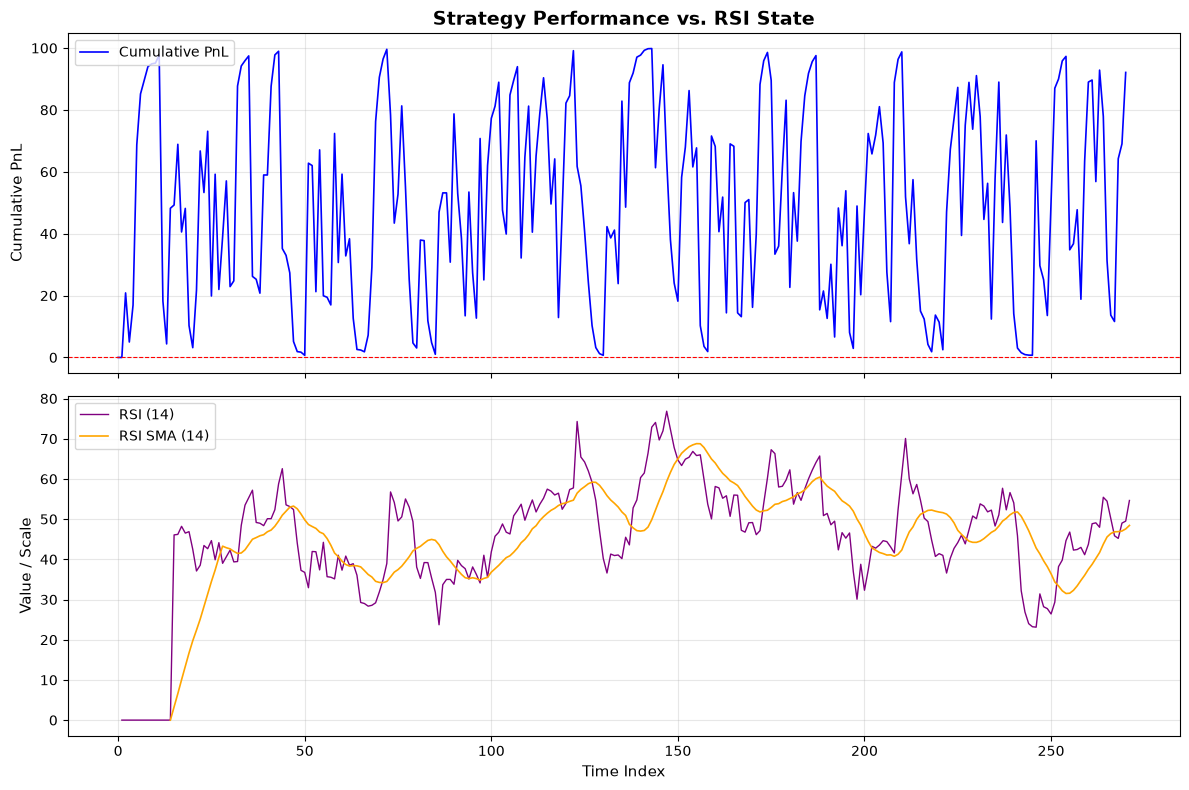

In [7]:

price_clean = np.asanyarray(df_price_1m['close'], dtype=float)
rsi_2 = get_wilders_rsi(np.diff(price_clean), 2)
rsi_14 = get_wilders_rsi(np.diff(price_clean), 14)
rsi_14_sma = sma(rsi_14, 14)

# 1. Calculate the indicators
price_clean = np.asanyarray(df_price_1m['close'], dtype=float)
diffs = np.diff(price_clean)

# 2. Get the raw RSI arrays
rsi_14_raw = get_wilders_rsi(diffs, 14)
rsi_14_sma_raw = sma(rsi_14_raw, 14)

# 3. Create full-length arrays filled with NaN
rsi_14 = np.full(len(df_price_1m), np.nan)
rsi_14_sma = np.full(len(df_price_1m), np.nan)

rsi_14[-len(rsi_14_raw):] = rsi_14_raw
rsi_14_sma[-len(rsi_14_sma_raw):] = rsi_14_sma_raw

# 5. Assign to DataFrame
df_price_1m['rsi_14'] = rsi_14
df_price_1m['sma_14'] = rsi_14_sma

# Call it with your variables, explicitly passing labels so the chart is clear
df_price_1m['rsi_above_sma'] = df_price_1m['rsi_14'] > df_price_1m['sma_14']

# 2. Identify where the condition changes (this creates a new "block" for every switch)
df_price_1m['block'] = (df_price_1m['rsi_above_sma'] != df_price_1m['rsi_above_sma'].shift()).cumsum()

# 3. Group by the condition and block to count the duration of each streak
streak_durations = df_price_1m.groupby(['rsi_above_sma', 'block']).size().reset_index(name='duration')

plot_two(
    primary_data=rsi_2, 
    secondary_data_1=rsi_14, 
    secondary_data_2=rsi_14_sma,
    primary_label="Cumulative PnL",
    secondary_label_1="RSI (14)",
    secondary_label_2="RSI SMA (14)",
    title="Strategy Performance vs. RSI State"
)